# CLIP ViT-B/32 — Phase I: Black-Box Behavioral Analysis

Participant: K52104490, k{}  
**Pair:** Human-only group  
**Model:** `openai/clip-vit-base-patch32`  
**Dataset:** Waterbirds (Group DRO)

This notebook documents the Phase I investigation of zero-shot bird classification, subgroup behavior across different backgrounds, and responses to text overlays. The analysis uses model inputs and outputs without examining internal representations.


## 1. Prepare the Environment

This section documents the Python environment, required libraries, GPU availability, and package versions used for the experiments.


In [24]:
import matplotlib.pyplot as plt
import numpy as np

from datasets import load_dataset
from transformers import CLIPProcessor, CLIPModel

import torch
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = "cuda" 
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute capability:", torch.cuda.get_device_capability(0))
else:
    device = "cpu"
    print("GPU: Not available")

PyTorch: 2.5.1
CUDA runtime: None
CUDA available: False
GPU: Not available


## 2. Load CLIP ViT-B/32

This section loads the pretrained CLIP ViT-B/32 model and its processor and verifies image–text similarity outputs with sample inputs.


In [25]:
labels = ["landbird", "waterbird"]
texts = ["a photo of a landbird.", "a photo of a waterbird."]

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
model = model.to(device)
model.eval()

processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

## 3. Prepare the Waterbirds Dataset

This section loads Waterbirds images, bird labels, background labels, and official dataset splits. It also records the label mappings and number of images in each subgroup.


Map: 100%|██████████| 5794/5794 [00:00<00:00, 17436.84 examples/s]


['image', 'label', 'place', 'bird']
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['landbird', 'waterbird']), 'place': ClassLabel(names=['land', 'water']), 'bird': ClassLabel(names=['Black_footed_Albatross', 'Laysan_Albatross', 'Sooty_Albatross', 'Groove_billed_Ani', 'Crested_Auklet', 'Least_Auklet', 'Parakeet_Auklet', 'Rhinoceros_Auklet', 'Brewer_Blackbird', 'Red_winged_Blackbird', 'Rusty_Blackbird', 'Yellow_headed_Blackbird', 'Bobolink', 'Indigo_Bunting', 'Lazuli_Bunting', 'Painted_Bunting', 'Cardinal', 'Spotted_Catbird', 'Gray_Catbird', 'Yellow_breasted_Chat', 'Eastern_Towhee', 'Chuck_will_Widow', 'Brandt_Cormorant', 'Red_faced_Cormorant', 'Pelagic_Cormorant', 'Bronzed_Cowbird', 'Shiny_Cowbird', 'Brown_Creeper', 'American_Crow', 'Fish_Crow', 'Black_billed_Cuckoo', 'Mangrove_Cuckoo', 'Yellow_billed_Cuckoo', 'Gray_crowned_Rosy_Finch', 'Purple_Finch', 'Northern_Flicker', 'Acadian_Flycatcher', 'Great_Crested_Flycatcher', 'Least_Flycatcher', 'Olive_sided_Flycatcher',

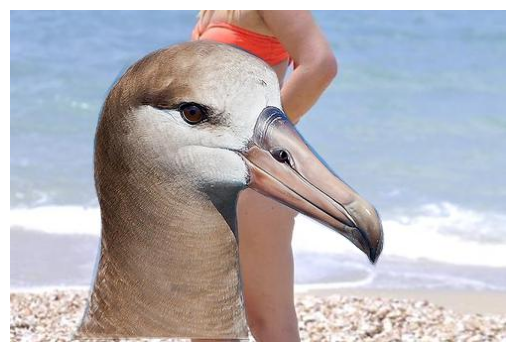

In [9]:
def correct_dataset(dataset):
    # Species incorrectly labeled as waterbirds
    incorrect_species = {
        "Eastern_Towhee",
        "Western_Meadowlark",
        "Western_Wood_Pewee"
    }

    # Bird IDs corresponding to these species
    bird_names = dataset.features["bird"].names

    incorrect_ids = {
        i for i, name in enumerate(bird_names)
        if any(species in name for species in incorrect_species)
    }

    # Correct labels
    def correct_labels(example):
        if example["bird"] in incorrect_ids:
            example["label"] = 0  # Landbird
        return example

    return dataset.map(correct_labels)


org_dataset = load_dataset(
    "grodino/waterbirds",
    split="test",
    cache_dir="./cache"
)

dataset = correct_dataset(org_dataset)

print(dataset.column_names)
print(dataset.features)
sample = dataset[0]
image = sample["image"]

plt.imshow(image)
plt.axis("off")
plt.show()

## 4. Run Baseline Classification

This section evaluates zero-shot classification on the Waterbirds test set using fixed waterbird and landbird text descriptions. Predicted labels and similarity scores are stored for analysis.


Actual bird: waterbird
Predicted bird: waterbird
Background: water
landbird: logit=21.7586, probability=0.37%
waterbird: logit=27.3470, probability=99.63%


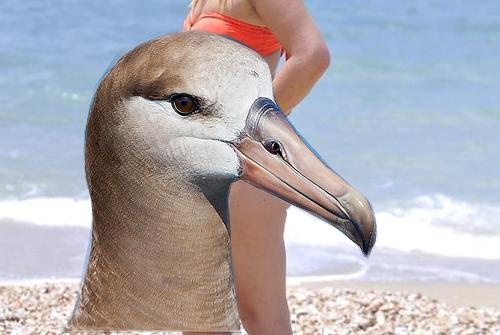

In [27]:
labels = ["landbird", "waterbird"]
texts = ["a photo of a landbird.", "a photo of a waterbird."]

inputs = processor(text=texts, images=image, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits_per_image
probs = logits.softmax(dim=1)

predicted_index = probs.argmax(dim=1).item()

print("Actual bird:", labels[sample["label"]])
print("Predicted bird:", labels[predicted_index])
print("Background:", "land" if sample["place"] == 0 else "water")

for i, label in enumerate(labels):
    print(
        f"{label}: "
        f"logit={logits[0, i].item():.4f}, "
        f"probability={probs[0, i].item():.2%}"
    )

display(image)

## 5. Calculate Evaluation Metrics

This section calculates classification accuracy, error counts, and the true-class similarity margin, m(x), for each image and subgroup.


In [28]:
import os
import pandas as pd
from tqdm.auto import tqdm

# run CLIP on a list of PIL images and return the logits (N x 2)
def get_logits(images, batch_size=64):
    all_logits = []
    for start in range(0, len(images), batch_size):
        batch = [img.convert("RGB") for img in images[start:start + batch_size]]
        inputs = processor(text=texts, images=batch, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            outputs = model(**inputs)
        all_logits.append(outputs.logits_per_image.cpu())
    return torch.cat(all_logits).numpy()

# classify the whole test set (results are saved so we only do this once)
logits_file = "baseline_test_logits.npy"
if os.path.exists(logits_file):
    test_logits = np.load(logits_file)
else:
    chunks = []
    chunk_size = 256
    for start in tqdm(range(0, len(dataset), chunk_size)):
        chunk = dataset[start:start + chunk_size]["image"]
        chunks.append(get_logits(chunk))
    test_logits = np.concatenate(chunks)
    np.save(logits_file, test_logits)

print(test_logits.shape)

(5794, 2)


In [29]:
bird_names = dataset.features["bird"].names
places = ["land", "water"]

df = pd.DataFrame({
    "label": list(dataset["label"]),
    "place": list(dataset["place"]),
    "bird": [bird_names[b] for b in dataset["bird"]],
})
df["group"] = [f"{labels[l]} on {places[p]}" for l, p in zip(df["label"], df["place"])]

n = len(df)
true_idx = df["label"].to_numpy()

df["logit_land"] = test_logits[:, 0]
df["logit_water"] = test_logits[:, 1]
df["pred"] = test_logits.argmax(axis=1)
df["correct"] = df["pred"] == df["label"]

# margin m(x) = logit of the true class - logit of the other class
# m(x) > 0 means correct, the larger the more confident
df["margin"] = test_logits[np.arange(n), true_idx] - test_logits[np.arange(n), 1 - true_idx]

probs = torch.tensor(test_logits).softmax(dim=1).numpy()
df["prob_true"] = probs[np.arange(n), true_idx]

df.head()

,label,place,bird,group,logit_land,logit_water,pred,correct,margin,prob_true
0,1,1,Black_footed_Albatross,waterbird on water,21.758635,27.346994,1,True,5.588360,0.996273
1,1,0,Black_footed_Albatross,waterbird on land,26.646864,28.333910,1,True,1.687046,0.843835
2,1,1,Black_footed_Albatross,waterbird on water,24.477694,28.654453,1,True,4.176760,0.984884
3,1,1,Black_footed_Albatross,waterbird on water,22.864155,27.466639,1,True,4.602484,0.990073
4,1,0,Black_footed_Albatross,waterbird on land,24.713821,26.547342,1,True,1.833521,0.862181


In [30]:
group_order = ["landbird on land", "landbird on water", "waterbird on land", "waterbird on water"]

print(f"Overall accuracy: {df['correct'].mean():.2%}")
print(f"Errors: {(~df['correct']).sum()} / {n}")
print(f"Mean margin: {df['margin'].mean():.3f}")

# metrics per subgroup
group_stats = df.groupby("group").agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    errors=("correct", lambda c: (~c).sum()),
    mean_margin=("margin", "mean"),
    median_margin=("margin", "median"),
    mean_prob_true=("prob_true", "mean"),
).reindex(group_order)

print(f"Worst-group accuracy: {group_stats['accuracy'].min():.2%} ({group_stats['accuracy'].idxmin()})")
print(f"Average group accuracy: {group_stats['accuracy'].mean():.2%}")
group_stats

Overall accuracy: 70.59%
Errors: 1704 / 5794
Mean margin: 1.319
Worst-group accuracy: 45.10% (landbird on water)
Average group accuracy: 75.90%


,n,accuracy,errors,mean_margin,median_margin,mean_prob_true
group,,,,,,
landbird on land,2255,0.876275,279,2.234452,2.361408,0.804007
landbird on water,2255,0.450998,1238,-0.384998,-0.303663,0.448127
waterbird on land,642,0.749221,161,1.493285,1.616922,0.702370
waterbird on water,642,0.959502,26,3.912106,4.160166,0.917729


## 6. Analyze Background Bias

This section compares results across the four bird-type and background-type subgroups, including classification errors and similarity-margin distributions.


In [31]:
# how often does the model say "waterbird" for each bird type / background?
water_rate = pd.crosstab(
    df["label"].map(lambda l: labels[l]),
    df["place"].map(lambda p: places[p]),
    values=df["pred"], aggfunc="mean",
)
print("Share of 'waterbird' predictions (rows = true bird, columns = background):")
print(water_rate.round(3))

# accuracy gap caused by the background, for each bird type
print()
for l, name in enumerate(labels):
    acc_land = df[(df["label"] == l) & (df["place"] == 0)]["correct"].mean()
    acc_water = df[(df["label"] == l) & (df["place"] == 1)]["correct"].mean()
    print(f"{name}: acc on land = {acc_land:.2%}, acc on water = {acc_water:.2%}, gap = {acc_water - acc_land:+.2%}")

Share of 'waterbird' predictions (rows = true bird, columns = background):
place       land  water
label                  
landbird   0.124  0.549
waterbird  0.749  0.960

landbird: acc on land = 87.63%, acc on water = 45.10%, gap = -42.53%
waterbird: acc on land = 74.92%, acc on water = 95.95%, gap = +21.03%


In [32]:
# bootstrap 95% confidence intervals for the subgroup accuracies
rng = np.random.default_rng(0)
n_boot = 1000

ci_rows = []
for g in group_order:
    c = df[df["group"] == g]["correct"].to_numpy()
    boot = [rng.choice(c, size=len(c), replace=True).mean() for _ in range(n_boot)]
    ci_rows.append({"group": g, "accuracy": c.mean(),
                    "ci_low": np.percentile(boot, 2.5), "ci_high": np.percentile(boot, 97.5)})

group_ci = pd.DataFrame(ci_rows).set_index("group")
group_ci

,accuracy,ci_low,ci_high
group,,,
landbird on land,0.876275,0.862528,0.890022
landbird on water,0.450998,0.431486,0.473171
waterbird on land,0.749221,0.714953,0.780413
waterbird on water,0.959502,0.943886,0.973520


In [33]:
# margin distribution per subgroup
margin_quantiles = df.groupby("group")["margin"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).reindex(group_order)
margin_quantiles.round(3)

,count,mean,std,min,10%,25%,50%,75%,90%,max
group,,,,,,,,,,
landbird on land,2255.0,2.234,1.969,-5.074,-0.221,0.885,2.361,3.569,4.683,8.339
landbird on water,2255.0,-0.385,2.190,-7.620,-3.286,-1.880,-0.304,1.077,2.359,6.655
waterbird on land,642.0,1.493,2.348,-6.619,-1.771,-0.005,1.617,3.203,4.312,8.856
waterbird on water,642.0,3.912,2.086,-4.606,1.242,2.748,4.160,5.373,6.318,8.278


In [34]:
# which species are misclassified the most? (only species with at least 20 test images)
species = df.groupby("bird").agg(
    label=("label", lambda l: labels[l.iloc[0]]),
    n=("correct", "size"),
    error_rate=("correct", lambda c: 1 - c.mean()),
    share_on_water=("place", "mean"),
    mean_margin=("margin", "mean"),
)
species = species[species["n"] >= 20].sort_values("error_rate", ascending=False)

print("Top 10 species by error rate:")
species.head(10).round(3)

Top 10 species by error rate:


,label,n,error_rate,share_on_water,mean_margin
bird,,,,,
Pied_Kingfisher,landbird,30,0.967,0.400,-2.176
Nighthawk,landbird,30,0.867,0.600,-2.283
White_breasted_Kingfisher,landbird,30,0.767,0.433,-1.449
Ringed_Kingfisher,landbird,30,0.733,0.567,-1.470
Chuck_will_Widow,landbird,26,0.731,0.385,-0.913
Brown_Creeper,landbird,29,0.724,0.483,-1.073
American_Crow,landbird,30,0.700,0.700,-1.041
Western_Meadowlark,waterbird,30,0.700,0.533,-0.722
Green_Kingfisher,landbird,30,0.667,0.433,-0.746


In [35]:
# error rate per species split by background - is the background effect the same for every species?
species_bg = df.groupby(["bird", "place"])["correct"].agg(lambda c: 1 - c.mean()).unstack()
species_bg.columns = ["error_on_land", "error_on_water"]
species_bg["label"] = species["label"]
species_bg = species_bg.dropna()
species_bg["diff"] = species_bg["error_on_land"] - species_bg["error_on_water"]

for name in labels:
    sub = species_bg[species_bg["label"] == name]
    print(f"{name}: error rate changes by more than 5% with the background in {(sub['diff'].abs() > 0.05).sum()} / {len(sub)} species")

species_bg.sort_values("diff", ascending=False).head(10).round(3)

landbird: error rate changes by more than 5% with the background in 151 / 152 species
waterbird: error rate changes by more than 5% with the background in 38 / 43 species


,error_on_land,error_on_water,label,diff
bird,,,,
Eastern_Towhee,0.875,0.357,waterbird,0.518
Black_Tern,0.500,0.000,waterbird,0.500
Forsters_Tern,0.462,0.000,waterbird,0.462
Western_Meadowlark,0.929,0.500,waterbird,0.429
Hooded_Merganser,0.462,0.059,waterbird,0.403
Pigeon_Guillemot,0.400,0.000,waterbird,0.400
Sooty_Albatross,0.385,0.000,waterbird,0.385
Black_footed_Albatross,0.353,0.000,waterbird,0.353
Horned_Puffin,0.333,0.000,waterbird,0.333


## 7. Visualize Baseline Results

This section presents subgroup performance charts, similarity-margin distributions, and examples of correct and incorrect predictions.


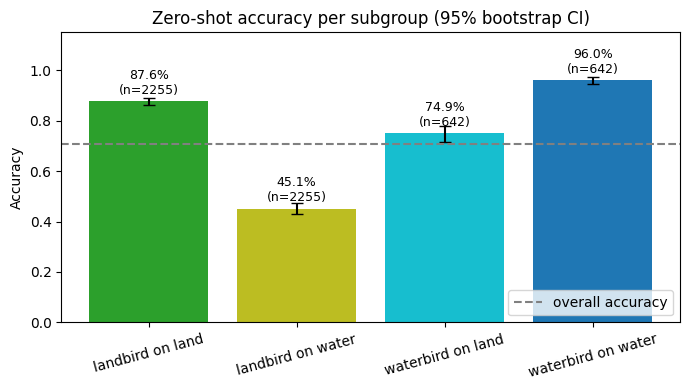

In [36]:
# subgroup accuracy with bootstrap confidence intervals
colors = ["tab:green", "tab:olive", "tab:cyan", "tab:blue"]

fig, ax = plt.subplots(figsize=(7, 4))
acc = group_ci["accuracy"]
yerr = [acc - group_ci["ci_low"], group_ci["ci_high"] - acc]
ax.bar(group_order, acc, yerr=yerr, capsize=4, color=colors)
ax.axhline(df["correct"].mean(), color="gray", linestyle="--", label="overall accuracy")
for i, g in enumerate(group_order):
    ax.text(i, acc[g] + 0.03, f"{acc[g]:.1%}\n(n={group_stats.loc[g, 'n']})", ha="center", fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Accuracy")
ax.set_title("Zero-shot accuracy per subgroup (95% bootstrap CI)")
ax.legend(loc="lower right")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

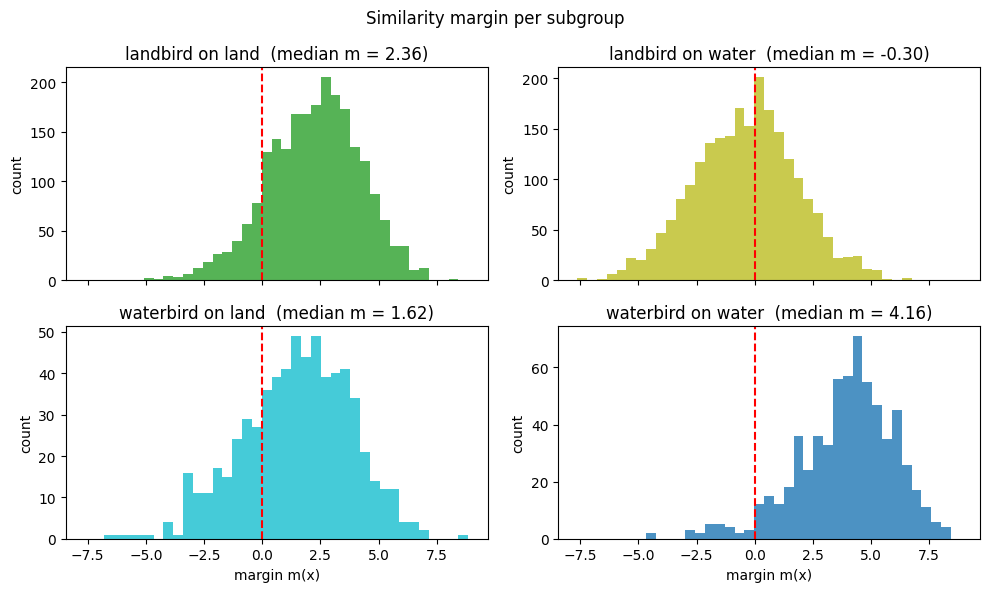

In [37]:
# margin distributions per subgroup (m(x) < 0 means the prediction is wrong)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
bins = np.linspace(df["margin"].min(), df["margin"].max(), 40)

for ax, g, c in zip(axes.flat, group_order, colors):
    m = df[df["group"] == g]["margin"]
    ax.hist(m, bins=bins, color=c, alpha=0.8)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{g}  (median m = {m.median():.2f})")
    ax.set_ylabel("count")

for ax in axes[1]:
    ax.set_xlabel("margin m(x)")
plt.suptitle("Similarity margin per subgroup")
plt.tight_layout()
plt.show()

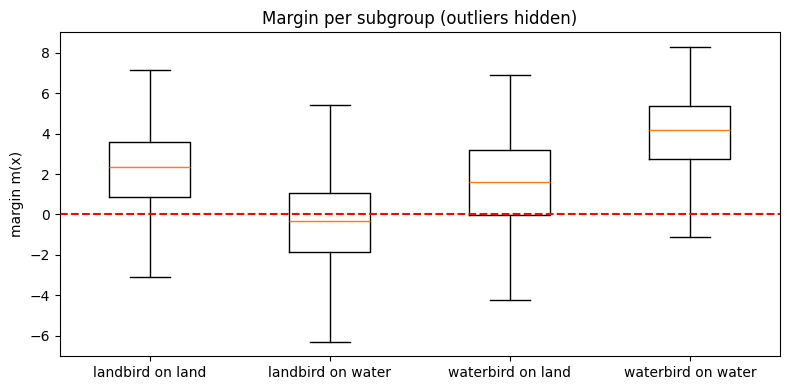

In [38]:
# the same margins in one plot to compare them directly
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df[df["group"] == g]["margin"] for g in group_order], showfliers=False)
ax.set_xticks(range(1, len(group_order) + 1), group_order)
ax.axhline(0, color="red", linestyle="--")
ax.set_ylabel("margin m(x)")
ax.set_title("Margin per subgroup (outliers hidden)")
plt.tight_layout()
plt.show()

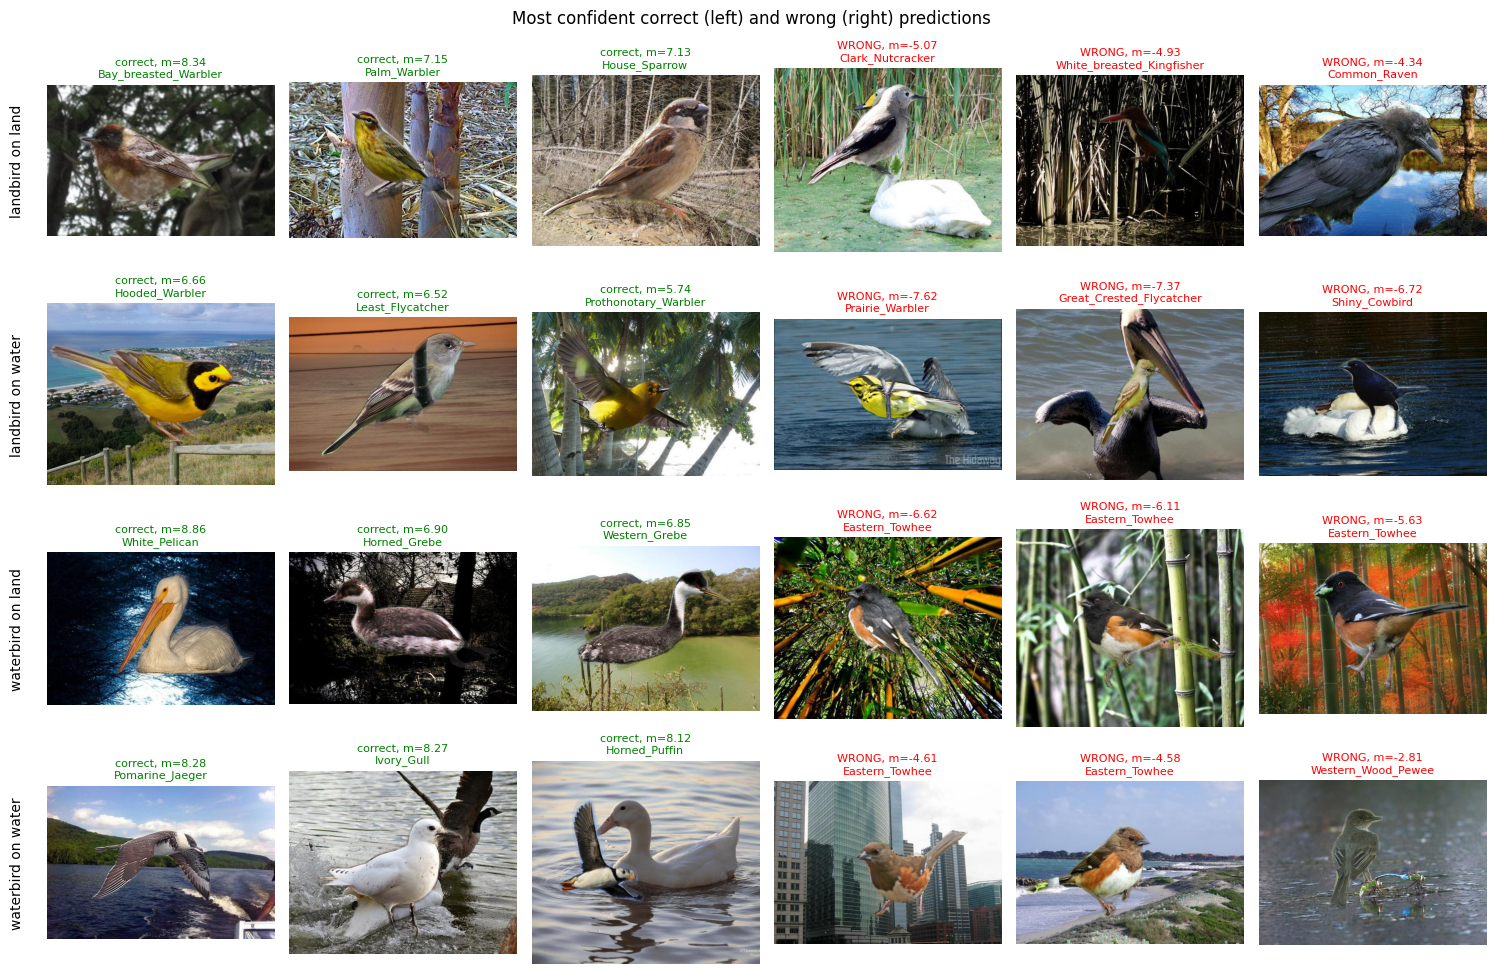

In [39]:
# examples: 3 most confident correct and 3 most confident wrong images per subgroup
n_show = 3
fig, axes = plt.subplots(len(group_order), 2 * n_show, figsize=(15, 10))

for row, g in enumerate(group_order):
    sub = df[df["group"] == g]
    best = sub[sub["correct"]].nlargest(n_show, "margin")
    worst = sub[~sub["correct"]].nsmallest(n_show, "margin")
    examples = list(best.iterrows()) + list(worst.iterrows())

    for col in range(2 * n_show):
        ax = axes[row, col]
        ax.axis("off")
        if col >= len(examples):
            continue
        idx, r = examples[col]
        ax.imshow(dataset[int(idx)]["image"])
        status = "correct" if r["correct"] else "WRONG"
        ax.set_title(f"{status}, m={r['margin']:.2f}\n{r['bird']}", fontsize=8,
                     color="green" if r["correct"] else "red")
    axes[row, 0].text(-0.1, 0.5, g, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=10)

plt.suptitle("Most confident correct (left) and wrong (right) predictions")
plt.tight_layout()
plt.show()

## 8. Generate Typographic Attacks

This section creates edited versions of selected Waterbirds images with correct, misleading, or neutral text overlays under recorded rendering settings.


In [40]:
from PIL import ImageDraw, ImageFont

# settings used for all text overlays
render_settings = {
    "font_size_ratio": 0.12,   # font size relative to image width
    "position": "bottom-center",
    "text_color": "black",
    "box_color": "white",
    "padding": 6,
}

# correct = true class name, misleading = other class name, neutral = unrelated word
def get_attack_text(condition, label):
    if condition == "correct":
        return labels[label]
    if condition == "misleading":
        return labels[1 - label]
    return "hello"

def add_text(image, text, settings=render_settings):
    img = image.convert("RGB").copy()
    draw = ImageDraw.Draw(img)
    w, h = img.size
    font = ImageFont.load_default(size=int(w * settings["font_size_ratio"]))

    left, top, right, bottom = draw.textbbox((0, 0), text, font=font)
    text_w, text_h = right - left, bottom - top
    pad = settings["padding"]
    x = (w - text_w) // 2
    y = h - text_h - 3 * pad

    draw.rectangle([x - pad, y - pad, x + text_w + pad, y + text_h + pad], fill=settings["box_color"])
    draw.text((x - left, y - top), text, fill=settings["text_color"], font=font)
    return img

In [41]:
# pick the same number of random images from each subgroup
n_per_group = 50
attack_df = df.groupby("group", group_keys=False).sample(n=n_per_group, random_state=0)
attack_idx = attack_df.index.to_numpy()
print(attack_df["group"].value_counts())

conditions = ["correct", "misleading", "neutral"]
original_images = [dataset[int(i)]["image"].convert("RGB") for i in attack_idx]

edited_images = {}
for cond in conditions:
    edited_images[cond] = [add_text(img, get_attack_text(cond, l))
                           for img, l in zip(original_images, attack_df["label"])]

print("Edited images per condition:", {c: len(v) for c, v in edited_images.items()})

group
landbird on land      50
landbird on water     50
waterbird on land     50
waterbird on water    50
Name: count, dtype: int64
Edited images per condition: {'correct': 200, 'misleading': 200, 'neutral': 200}


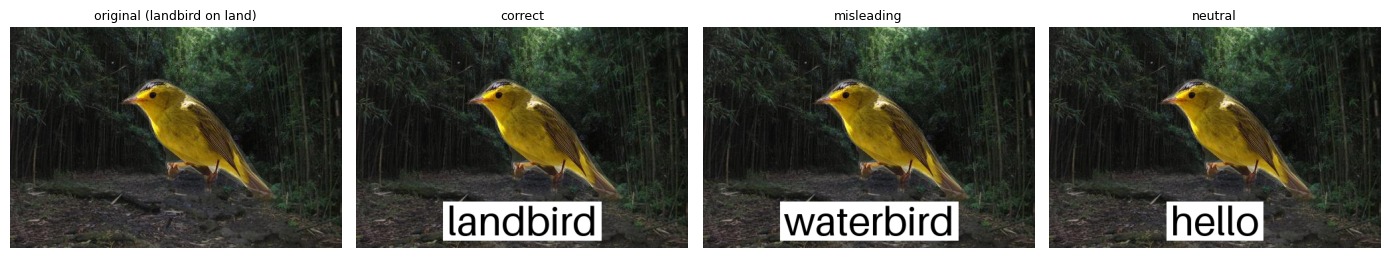

In [42]:
# show one example of each condition
example = 0
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(original_images[example])
axes[0].set_title(f"original ({attack_df['group'].iloc[example]})", fontsize=9)
for ax, cond in zip(axes[1:], conditions):
    ax.imshow(edited_images[cond][example])
    ax.set_title(cond, fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Evaluate Typographic Attacks

This section compares model outputs for original and text-overlaid images, measuring prediction changes and margin shifts, Δm(x).


In [43]:
# the original predictions are already in test_logits
orig_logits = test_logits[attack_idx]
y = attack_df["label"].to_numpy()
rows = np.arange(len(y))

orig_pred = orig_logits.argmax(axis=1)
orig_margin = orig_logits[rows, y] - orig_logits[rows, 1 - y]

attack_results = []
for cond in conditions:
    new_logits = get_logits(edited_images[cond])
    new_pred = new_logits.argmax(axis=1)
    new_margin = new_logits[rows, y] - new_logits[rows, 1 - y]

    attack_results.append(pd.DataFrame({
        "idx": attack_idx,
        "group": attack_df["group"].to_numpy(),
        "bird": attack_df["bird"].to_numpy(),
        "label": y,
        "condition": cond,
        "text": [get_attack_text(cond, l) for l in y],
        "orig_pred": orig_pred,
        "new_pred": new_pred,
        "orig_margin": orig_margin,
        "new_margin": new_margin,
    }))

attack_results = pd.concat(attack_results, ignore_index=True)
attack_results["delta_m"] = attack_results["new_margin"] - attack_results["orig_margin"]
attack_results["flipped"] = attack_results["orig_pred"] != attack_results["new_pred"]
attack_results["orig_correct"] = attack_results["orig_pred"] == attack_results["label"]
attack_results["new_correct"] = attack_results["new_pred"] == attack_results["label"]

attack_results.to_csv("typographic_attack_results.csv", index=False)
attack_results.head()

,idx,group,bird,label,condition,text,orig_pred,new_pred,orig_margin,new_margin,delta_m,flipped,orig_correct,new_correct
0,5203,landbird on land,Wilson_Warbler,0,correct,landbird,0,0,3.392239,7.101536,3.709297,False,True,True
1,3663,landbird on land,Seaside_Sparrow,0,correct,landbird,0,0,1.010225,6.634140,5.623915,False,True,True
2,2142,landbird on land,Dark_eyed_Junco,0,correct,landbird,0,0,4.692738,4.692738,0.000000,False,True,True
3,3458,landbird on land,Grasshopper_Sparrow,0,correct,landbird,0,0,3.216236,8.638121,5.421885,False,True,True
4,332,landbird on land,Indigo_Bunting,0,correct,landbird,0,0,1.591879,6.690590,5.098711,False,True,True


In [44]:
# overall effect of each text condition
summary = attack_results.groupby("condition").agg(
    acc_before=("orig_correct", "mean"),
    acc_after=("new_correct", "mean"),
    flip_rate=("flipped", "mean"),
    mean_delta_m=("delta_m", "mean"),
    median_delta_m=("delta_m", "median"),
).reindex(conditions)
summary.round(3)

,acc_before,acc_after,flip_rate,mean_delta_m,median_delta_m
condition,,,,,
correct,0.785,0.950,0.165,3.427,3.685
misleading,0.785,0.115,0.670,-4.574,-5.217
neutral,0.785,0.775,0.090,-0.427,-0.077


In [45]:
# flip rate and margin shift per subgroup and condition
flip_table = attack_results.pivot_table(index="group", columns="condition", values="flipped", aggfunc="mean").reindex(group_order)[conditions]
delta_table = attack_results.pivot_table(index="group", columns="condition", values="delta_m", aggfunc="mean").reindex(group_order)[conditions]

print("Flip rate:")
print(flip_table.round(3))
print()
print("Mean margin change (delta m):")
print(delta_table.round(3))

Flip rate:
condition           correct  misleading  neutral
group                                           
landbird on land       0.04        0.82     0.00
landbird on water      0.42        0.32     0.16
waterbird on land      0.18        0.64     0.20
waterbird on water     0.02        0.90     0.00

Mean margin change (delta m):
condition           correct  misleading  neutral
group                                           
landbird on land      4.064      -4.391    0.112
landbird on water     4.236      -2.605    0.582
waterbird on land     3.159      -5.032   -0.888
waterbird on water    2.249      -6.265   -1.514


In [46]:
# flips split by direction: wrong -> correct (fixed) and correct -> wrong (broken)
attack_results["fixed"] = ~attack_results["orig_correct"] & attack_results["new_correct"]
attack_results["broken"] = attack_results["orig_correct"] & ~attack_results["new_correct"]

direction = attack_results.groupby(["condition", "group"])[["fixed", "broken"]].sum()
direction["n_orig_wrong"] = attack_results.groupby(["condition", "group"])["orig_correct"].apply(lambda c: (~c).sum())
direction["n_orig_correct"] = attack_results.groupby(["condition", "group"])["orig_correct"].sum()
direction

fixed  broken  n_orig_wrong  n_orig_correct
condition  group                                                          
correct    landbird on land        2       0             3              47
           landbird on water      21       0            26              24
           waterbird on land       9       0            12              38
           waterbird on water      1       0             2              48
misleading landbird on land        0      41             3              47
           landbird on water       0      16            26              24
           waterbird on land       0      32            12              38
           waterbird on water      0      45             2              48
neutral    landbird on land        0       0             3              47
           landbird on water       8       0            26              24
           waterbird on land       0      10            12              38
           waterbird on water      0       0             2              48

### Findings (Sections 5–9)

**Baseline performance.** Zero-shot CLIP achieves an overall test accuracy of 70.6%. However, this figure does not fully reflect the differences in performance across the four groups. The model performs well when the bird and its background are consistent, reaching 87.6% accuracy for landbirds on land and 96.0% for waterbirds on water. Performance decreases considerably when the bird and background do not match. In particular, accuracy for landbirds on water drops to 45.1%, falling below chance level, while waterbirds on land achieve 74.9%.

**Background bias.** The results suggest that the background has a substantial influence on the model's predictions, often shifting them towards the waterbird category. For landbirds, the proportion of images classified as waterbirds increases from 12% when the birds are photographed on land to 55% when they appear on water. The margin distributions provide further evidence of this bias. For landbirds on water, the entire distribution is shifted towards negative values, with a median margin of −0.30. This suggests that the effect is not limited to a small number of difficult examples but represents a broader pattern across the dataset. The same tendency appears across nearly all species. Kingfishers, nighthawks, and crows are among the most affected, despite being classified as landbirds.

**Typographic attacks.** Adding text to the images has an even stronger effect on model predictions than changing the background. Misleading text causes 67% of predictions to change and reduces accuracy from 78.5% to 11.5%. In contrast, text that provides the correct label increases accuracy to 95%. Notably, it corrects 21 of the 26 initially misclassified landbird-on-water images, suggesting that textual information can override the visual context.

Neutral text (e.g., "hello") has little effect on the groups that are already classified correctly. However, it still changes the predictions for 16–20% of images in the two conflict groups. This suggests that predictions in these groups are less stable and that even semantically unrelated text can influence the model when an image is already close to the decision boundary.

Interestingly, landbirds on water have the lowest prediction flip rate under misleading text (32%). This is likely because approximately half of these images are already incorrectly classified as waterbirds. As a result, the misleading text reinforces an existing prediction rather than causing the model to change its decision.

**Overall interpretation.** Taken together, these findings indicate that CLIP relies considerably on contextual information, including backgrounds and text, rather than consistently basing its predictions on the bird itself. Images in which the background conflicts with the bird category appear to be particularly vulnerable to these influences. These observations motivate the second phase of the study, which examines the model's internal representations to better understand the mechanisms behind this behaviour.

**Limitations.** The typographic attacks were conducted on a subset of 50 images per group, using a single font size, text position, and prompt template. Consequently, it remains unclear whether the observed effects would change under different configurations. Further experiments are needed to determine how sensitive the results are to these design choices.

## 10. Visualize Attack Results

This section presents original-versus-edited image comparisons and visualizations of prediction-flip rates and similarity-margin changes.


In [47]:
# Write your code here

## 11. Investigate Important Patterns

This section examines selected patterns observed in the subgroup and text-overlay experiments, including their relationships with image and experimental characteristics.


In [48]:
# Write your code here

## 12. Prepare Midpoint Submission

This section collects the experimental setup, visualizations, observations, limitations, and reproducibility details for the Phase I midpoint submission.


In [49]:
# Write your code here

## References

- [CLIP ViT-B/32 checkpoint](https://huggingface.co/openai/clip-vit-base-patch32)
- [Official CLIP repository](https://github.com/openai/CLIP)
- [CLIP research paper](https://arxiv.org/abs/2103.00020)
- [Waterbirds / Group DRO repository](https://github.com/kohpangwei/group_DRO)

Waterbirds subgroup comparisons use different images; controlled swaps of the same foreground across backgrounds require an additional image-editing procedure.
